In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

In [2]:
df = pd.read_csv(os.path.join('../Data/2026/M_curves_M3.csv'))
print(df.shape)
df.head()

(3015, 4)


,FM,P,W,M
0,9,1,0.0,0.000000
1,9,1,0.1,0.125499
2,9,1,0.2,0.246430
3,9,1,0.3,0.362920
4,9,1,0.4,0.475088


In [3]:
df_real = pd.read_csv(os.path.join('../Data/2026/All_p_w_m.csv'))
df_real = df_real.groupby(['FM', 'P', 'W']).M.mean().reset_index()
df_real.W = np.round(df_real.W, 1)
print(df_real.shape)
df_real.head()

(75, 4)


,FM,P,W,M
0,9,1,0.0,0.000000
1,9,1,0.2,0.245257
2,9,1,0.4,0.447675
3,9,1,0.6,0.634279
4,9,1,0.8,0.808251


In [4]:
def estimate_M_values(Mk, omega, n_p=5, lr=0.1, epoch=100000, tol=1e-5):
    """Take M at P=k as the best match and adjust M at P=i and P=j so that
    Mk^2 = C Mi^2 + D Mj^2 (C + D = 1), i.e. M_P^2 = X + Y / P^2. Mi, Mj, Mk are
    paired element-wise (same z). Gradient descent on r^2, r = Mk^2 - C Mi^2 - D Mj^2,
    stops after `epoch` steps or once the loss changes by less than `tol`.
    Returns Mi, Mj and the loss per epoch: loss_M2 = RMS of r (M^2 units) and
    loss_M = RMSE of sqrt(C Mi^2 + D Mj^2) against Mk (M units), both after the step."""
    
    if lr <= 0 or epoch < 1:
        raise ValueError(f'need lr > 0 and epoch >= 1, got lr={lr}, epoch={epoch}')
    
    i,j,k=1,2,3
    
    Mi = np.array((k**2/i**2)*Mk*0.5, dtype=float)
    Mj = np.array((k**2/j**2)*Mk*0.5, dtype=float)
    Mk = np.array(Mk, dtype=float)

    A = j**2 / (j**2 - i**2)
    B = k**2 / (k**2 - i**2)
    C = A / B
    D = i**2 / k**2

    loss = []
    prev = np.inf
    for ep in range(1, epoch + 1):
        resid = Mk - ((1-C) * Mi + C * Mj)
        # dL/dMi = -2(1-C)r, dL/dMj = -2Cr
        Mi = Mi + 2 * lr * resid * (1-C)
        Mj = Mj + 2 * lr * resid * C

        Est_Mk = (1-C) * Mi + C * Mj
        loss_M = np.sqrt(np.mean((Mk - Est_Mk) ** 2))
        loss.append({'epoch': ep, 'loss_M': loss_M})
        
        if abs(prev - loss_M) < tol:
            break
        prev = loss_M

    I = (Mk - D*Mi) / (1-D)

    m_dict = {'W':omega, 'M1':Mi, 'M2':Mj, 'M3':Mk}

    for j in range(k+1, n_p+1):
        A = j**2 / (j**2 - i**2)
        m_dict[f'M{j}'] = (I + (A-1)*Mi) / A

    m_dict['I'] = I

    return m_dict, pd.DataFrame(loss)



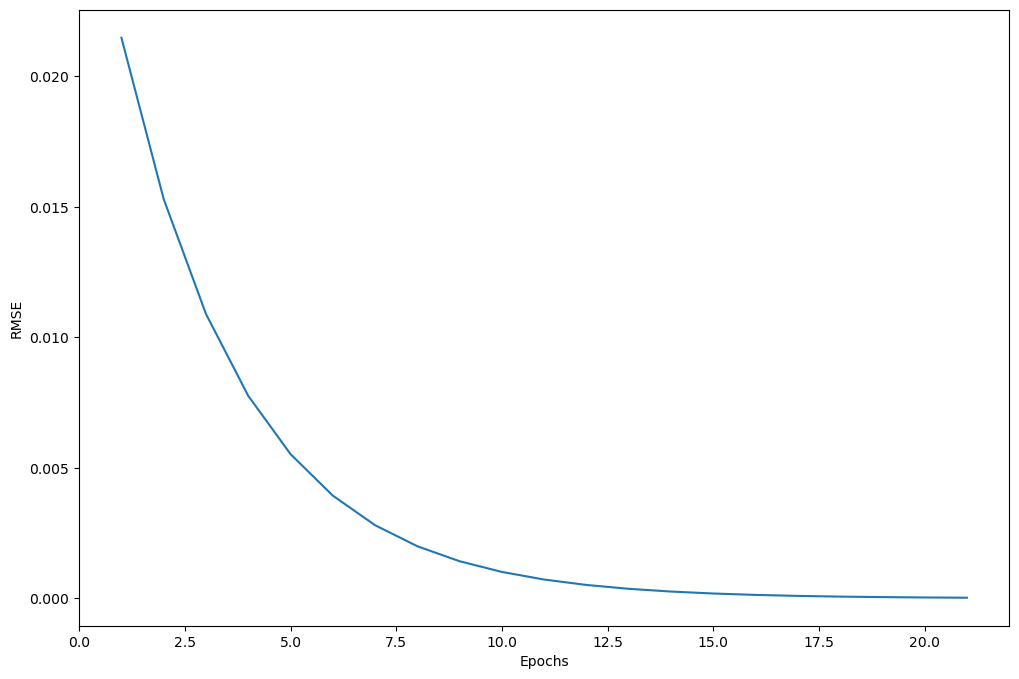

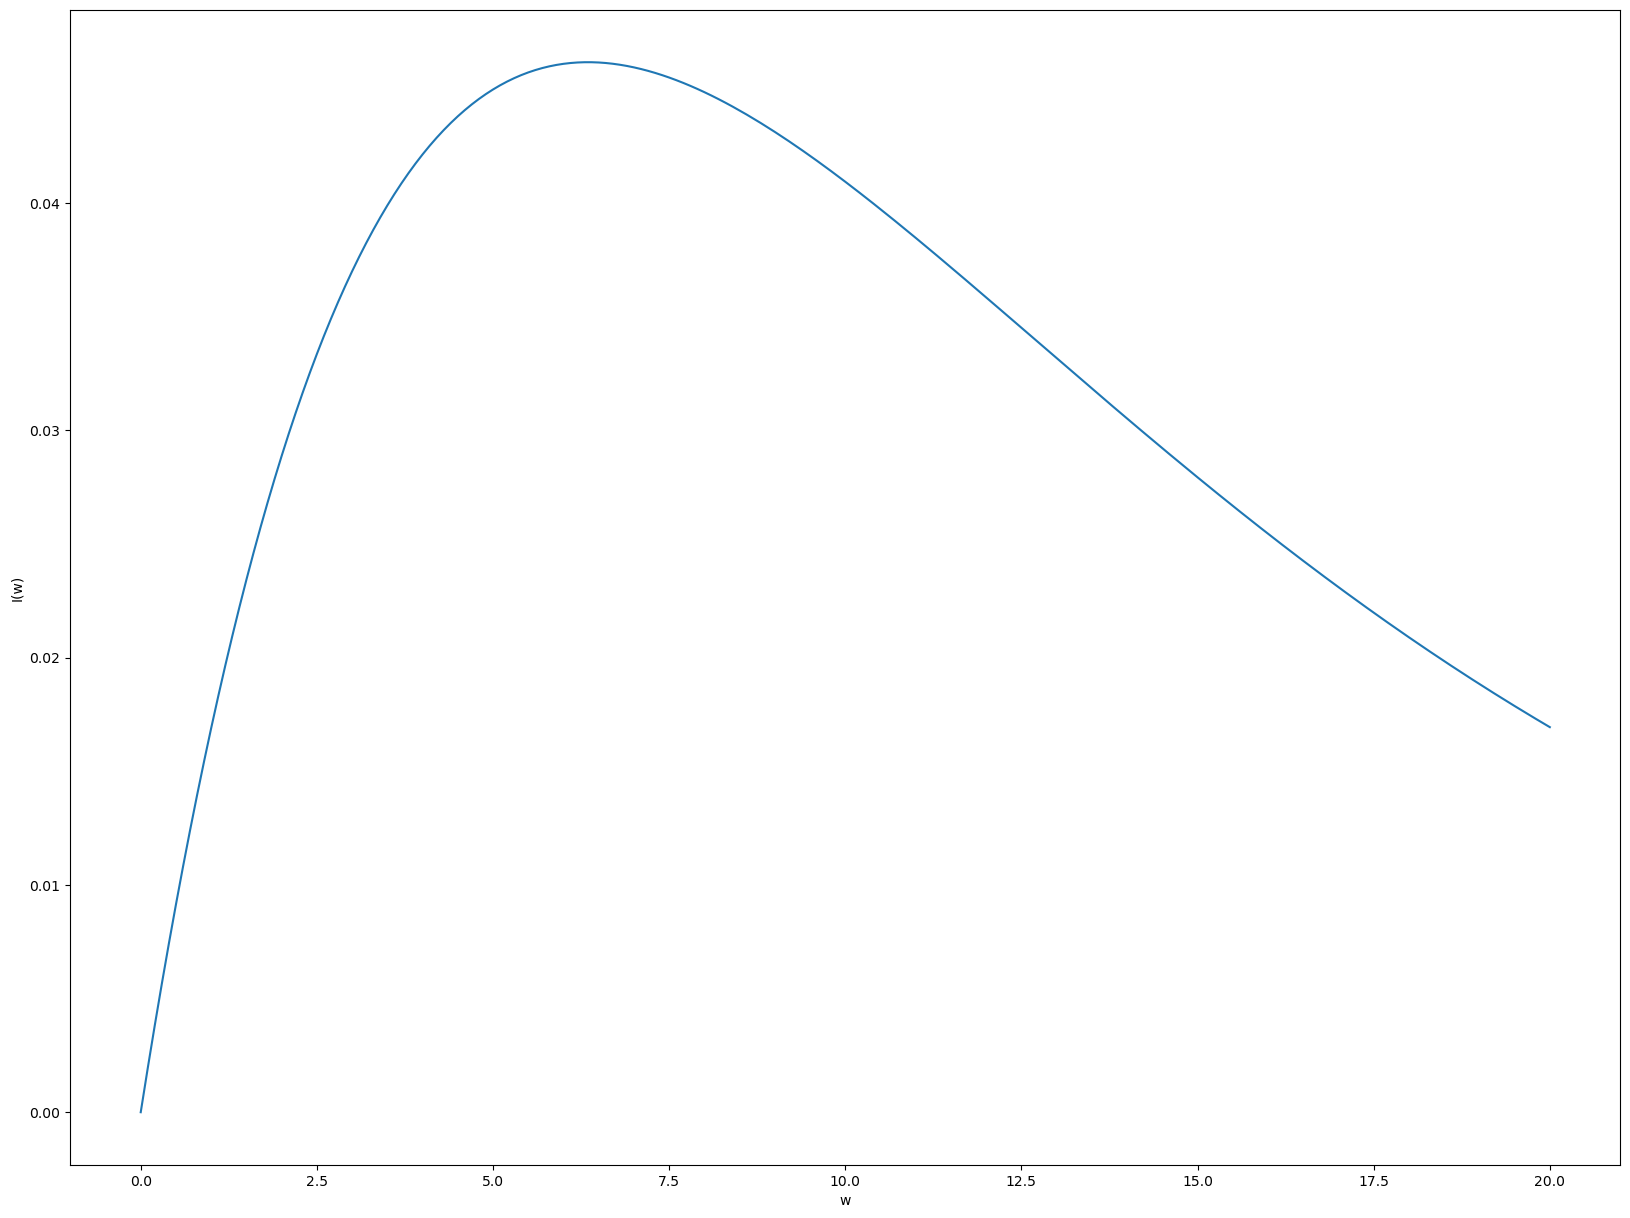

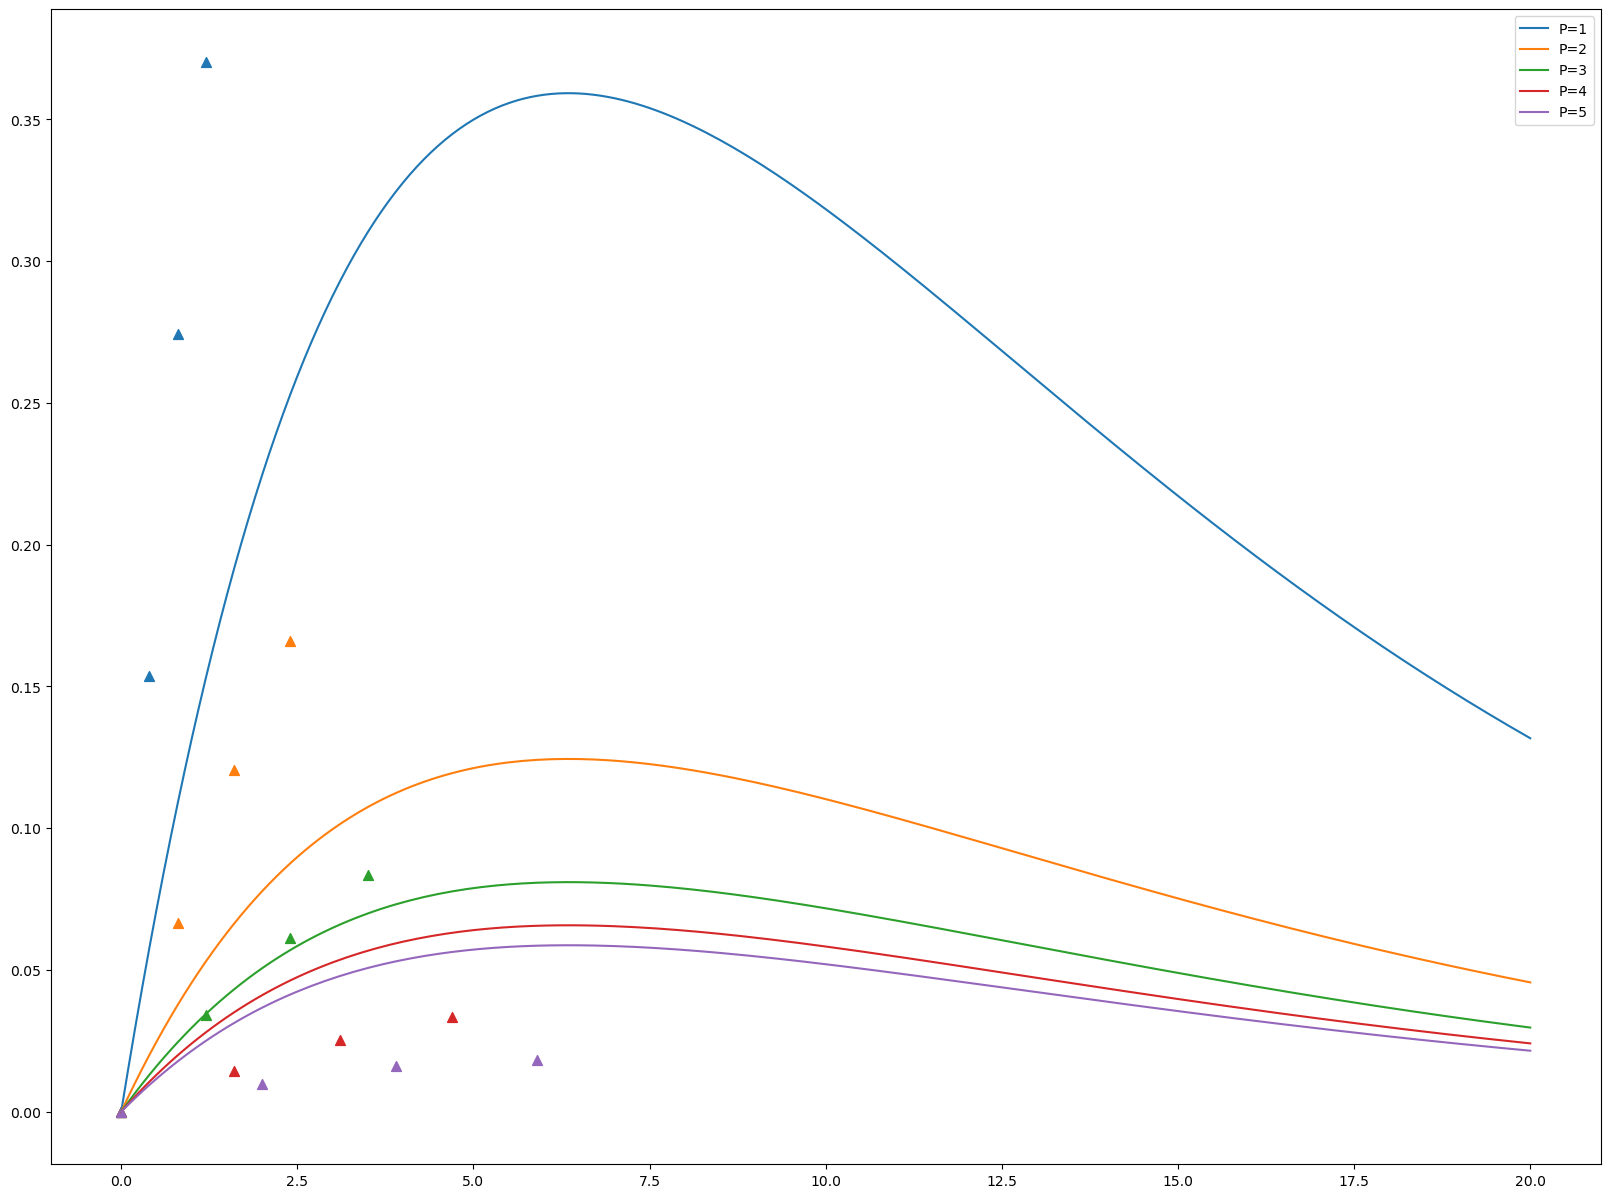

In [8]:
fm = 15
df9 = df[df.FM==fm]
dfr9 = df_real[df_real.FM==fm]
w = df9.W.unique()
df_est, df_loss = estimate_M_values(df9[df9.P==3].M.values, w, n_p=5)

plt.figure(figsize=(12,8))
plt.plot(df_loss.epoch, df_loss.loss_M, label='Loss M')
plt.xlabel('Epochs')
plt.ylabel('RMSE')
plt.show()

plt.figure(figsize=(20,15))
plt.plot(df_est['W'], df_est['I'])
plt.xlabel('w')
plt.ylabel('I(w)')
plt.show()

plt.figure(figsize=(20, 15))
for p in range(1,6):
    plt.plot(df_est['W'], df_est[f'M{p}'], label=f'P={p}')
    plt.scatter(dfr9[dfr9.P==p].W, dfr9[dfr9.P==p].M, s=50, marker='^')

plt.legend()
plt.show()